In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'config.json').exists(), 'Open the notebook inside fraud-detection.'

def read_report(name):
    return pd.read_csv(ROOT / 'reports' / name)

audit = json.loads((ROOT / 'reports/data_audit.json').read_text())
metadata = json.loads((ROOT / 'models/metadata.json').read_text())

## 1. Sources and the SQL LEFT JOIN

Data loading, the LEFT JOIN, and SQL quality checks were executed in local PostgreSQL. The execution engine and database version are recorded in reports/data_audit.json.

In [2]:
source = json.loads((ROOT / 'reports/source_manifest.json').read_text())
display(pd.DataFrame(source['sources']).T[['rows', 'source_sha256']])
print('Execution engine:', audit['execution_engine'])
print('Transaction rows:', audit['transaction_rows'])
print('Joined rows:', audit['joined_rows'])
print('Missing identity rows:', audit['missing_identity_rows'])
assert audit['transaction_rows'] == audit['joined_rows']
gates = read_report('sql_quality.csv')
display(gates)
assert gates['passed'].all()

,rows,source_sha256
transaction,590540,3a5c83ab6b3cc13dcabe5ffa9f522307fd5f7f7b6e6f6a...
identity,144233,b63c725d8377be90a995268d97f347c17d456b95db4580...


Execution engine: native_postgresql
Transaction rows: 590540
Joined rows: 590540
Missing identity rows: 446307


,gate,actual,passed
0,transaction_rows,590540,True
1,identity_rows,144233,True
2,transaction_duplicate_keys,0,True
3,identity_duplicate_keys,0,True
4,joined_rows,590540,True
5,invalid_labels,0,True
6,invalid_time,0,True
7,orphan_identity_keys,0,True


## 2. Missingness and Fraud Prevalence

`missing_pct` is missing count / row count × 100. Missing identity is expected and must not cause transaction rows to disappear.

,feature,missing_count,missing_pct
21,r_emaildomain,453249,76.751617
22,device_type,449730,76.155722
13,id_02,449668,76.145223
24,id_15,449555,76.126088
23,id_12,446307,75.576083
1,dist1,352271,59.652352
9,d2,280797,47.549192
10,d3,262878,44.514851
20,p_emaildomain,94456,15.994852
12,d15,89113,15.090087


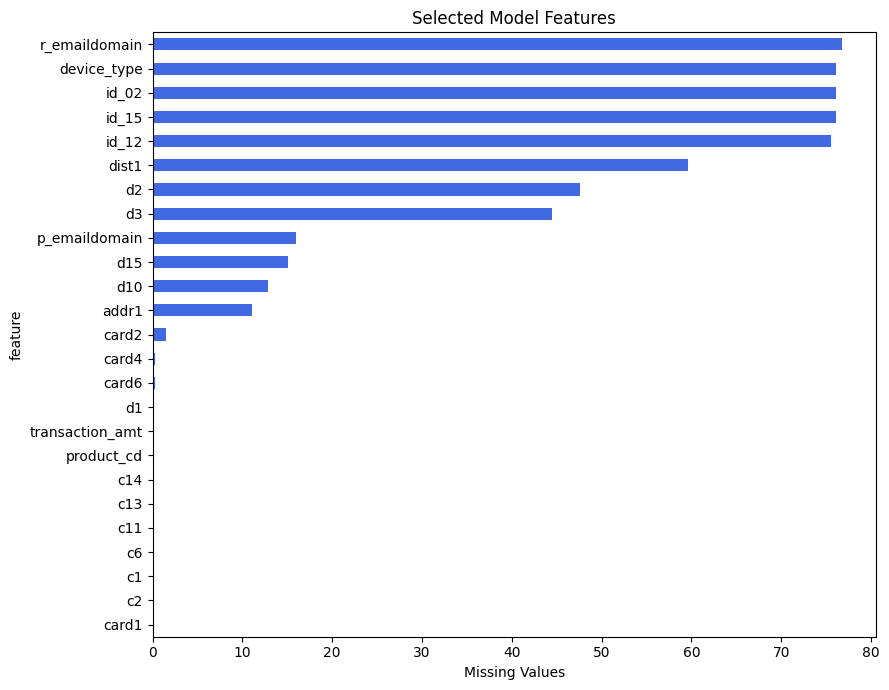

Overall Labeled Fraud Prevalence: 3.4990%


In [3]:
missing = read_report('missingness.csv').sort_values('missing_pct', ascending = False)
display(missing)
ax = missing.set_index('feature')['missing_pct'].sort_values().plot.barh(figsize = (9, 7), color = 'royalblue')
ax.set_xlabel('Missing Values')
ax.set_title('Selected Model Features')
plt.tight_layout()
plt.show()
print(f'Overall Labeled Fraud Prevalence: {audit["fraud_prevalence"]:.4%}')

,product_cd,transactions,fraud_count,fraud_rate,mean_amount,identity_coverage
0,C,68519,8008,0.116873,42.872353,0.907661
1,H,33024,1574,0.047662,73.170058,0.996487
2,R,37699,1426,0.037826,168.306188,0.995995
3,S,11628,686,0.058996,60.269487,0.996302
4,W,439670,8969,0.020399,153.158554,0.000000


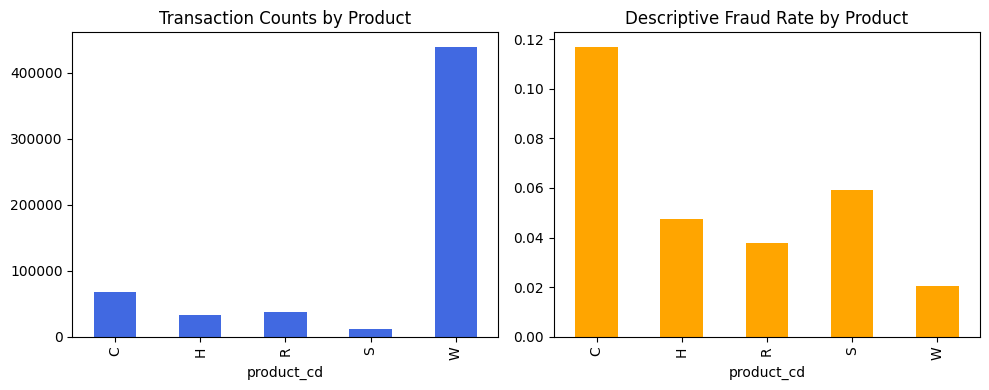

In [4]:
kpis = read_report('data_kpis.csv')
display(kpis)
fig, axes = plt.subplots(1, 2, figsize = (10, 4))
kpis.plot.bar(x = 'product_cd', y = 'transactions', ax = axes[0], legend = False, color = 'royalblue')
kpis.plot.bar(x = 'product_cd', y = 'fraud_rate', ax = axes[1], legend = False, color = 'orange')
axes[0].set_title('Transaction Counts by Product')
axes[1].set_title('Descriptive Fraud Rate by Product')
plt.tight_layout()
plt.show()

These whole-dataset summaries describe the supplied data. They are not training features and were not used to select the feature list. Product-code meanings remain anonymized.

## 3. Chronological Split

The row targets are 60/20/20. All records at a boundary timestamp stay in the same partition.
Preprocessing fits training rows only. TransactionDT is an offset, not a calendar timestamp.

In [5]:
splits = read_report('split_summary.csv').set_index('split')
display(splits)
assert splits.loc['train', 'time_max'] < splits.loc['validation', 'time_min']
assert splits.loc['validation', 'time_max'] < splits.loc['test', 'time_min']
assert splits['rows'].sum() == audit['transaction_rows']
assert 'is_fraud' not in metadata['features']
assert 'transaction_id' not in metadata ['features']
assert 'transaction_dt' not in metadata['features']
print('Frozen boundaries:', metadata['boundaries'])

,rows,fraud_count,prevalence,time_min,time_max
split,,,,,
train,354324,11988,0.033833,86400,8745772
validation,118108,4611,0.039041,8745798,12192842
test,118108,4064,0.034409,12192900,15811131


Frozen boundaries: {'train_end_exclusive': 8745798, 'validation_end_exclusive': 12192900}


## 4. Baseline vs. Improved Model 

Average Precision (AP) summarizes ranking quality under class imbalance. It is not the same as trapezoidal PR-AUC.
Use prevalence as context, and read precision/recall with the alert budget. Accuracy alone would be misleading here.

,model,split,prevalence,average_precision,roc_auc,k,precision_at_k,recall_at_k
0,dummy,validation,0.039041,0.039041,0.500000,2363,0.030893,0.015832
1,logistic,validation,0.039041,0.294138,0.818704,2363,0.435887,0.223379
2,lightgbm,validation,0.039041,0.556893,0.898672,2363,0.782903,0.401214
3,dummy,test,0.034409,0.034409,0.500000,2363,0.046128,0.026821
4,logistic,test,0.034409,0.192873,0.772496,2363,0.305121,0.177411
5,lightgbm,test,0.034409,0.447351,0.859707,2363,0.620821,0.360974


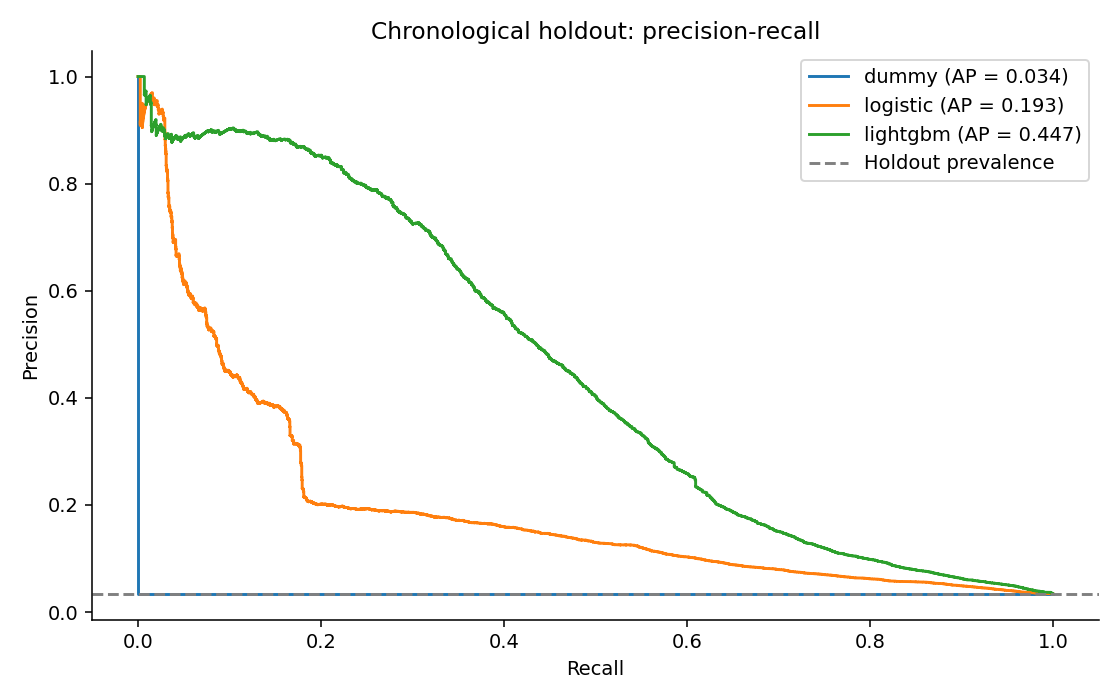

In [6]:
metrics = read_report('metrics.csv')
columns = ['model', 'split', 'prevalence', 'average_precision', 'roc_auc', 'k', 'precision_at_k', 'recall_at_k']
display(metrics[columns])
display(Image(filename = str(ROOT / 'reports/figures/precision_recall.png')))

## 5. Two Different Alert Policies

Top-K ranks the whole holdout and selects ceil(2% × rows), with transaction ID breaking ties.
The API uses a separate strict score threshold frozen on validation. The number of holdout alerts may differ from K.

,policy,alerts,true_positives,false_positives,false_negatives
0,Top 2% of full holdout,2363,1467,896,2597
1,Frozen validation threshold,2002,1357,645,2707


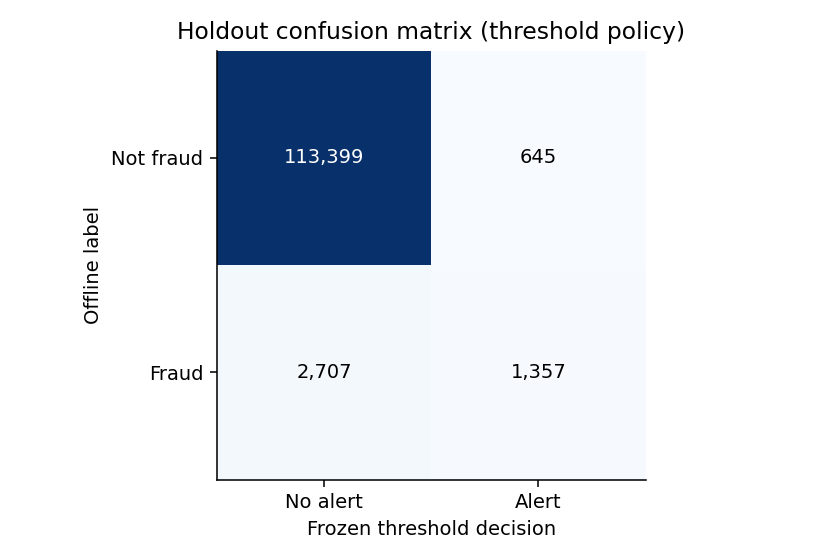

In [7]:
final = metrics.query('model == "lightgbm" and split == "test"').iloc[0]
comparison = pd.DataFrame({
    'policy': ['Top 2% of full holdout', 'Frozen validation threshold'],
    'alerts': [final['k'], final['threshold_alerts']],
    'true_positives': [final['topk_tp'], final['threshold_tp']],
    'false_positives': [final['topk_fp'], final['threshold_fp']],
    'false_negatives': [final['topk_fn'], final['threshold_fn']]
})
display(comparison)
display(Image(filename = str(ROOT / 'reports/figures/confusion_matrix.png')))

## 6. Error Slices and Explanations

Slices below use the frozen threshold. Native TreeSHAP contributions are in raw log-odds, not percentages.
Positive/negative contributions affect the model score; they are not causal proof of fraud.

,product_cd,transactions,fraud,alerts,tp,fp,fn,precision,recall
0,C,12109,1617,1310,942,368,675,0.719084,0.582560
1,H,3333,197,125,70,55,127,0.560000,0.355330
2,R,5496,257,169,131,38,126,0.775148,0.509728
3,S,3501,183,57,52,5,131,0.912281,0.284153
4,W,93669,1810,341,162,179,1648,0.475073,0.089503


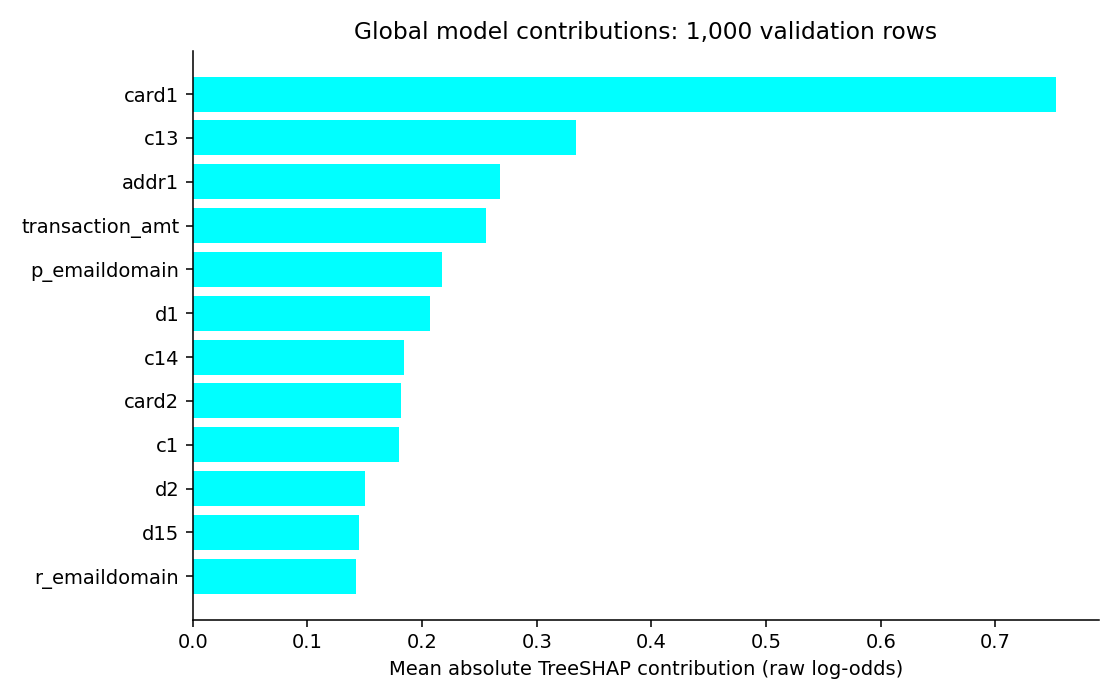

true_positive ID 3499636 label 1 score 0.998308


,raw_log_odds
c1,1.841480
r_emaildomain,1.773787
c13,1.600371
c14,1.365571
transaction_amt,1.292894


false_positive ID 3460709 label 0 score 0.992733


,raw_log_odds
c1,2.844829
c13,1.531480
r_emaildomain,1.276759
card1,0.649306
addr1,0.537212


false_negative ID 3528633 label 1 score 0.38293


,raw_log_odds
c14,1.460133
card2,0.926283
addr1,0.725699
r_emaildomain,0.658327
c13,0.445112


In [8]:
display(read_report('error_slices.csv'))
display(Image(filename = str(ROOT / 'reports/figures/global_shap.png')))
cases = json.loads((ROOT / 'reports/local_explanations.json').read_text())
for case in cases:
    print(case['case'], 'ID', case['transaction_id'], 'label', case['is_fraud'], 'score', round(case['risk_score'], 6))
    contributions = pd.Series(case['contributions'])
    display(contributions.loc[contributions.abs().sort_values(ascending = False).index].head(5).to_frame('raw_log_odds'))

## 7. Power BI Reconciliation

The export contains labels for offline reporting only. These labels never enter the API payload.
The demo queue is enriched and must not replace the full holdout when reporting performance.

In [9]:
fact = pd.read_csv(ROOT / 'powerbi/exports/fact_scores.csv')
assert len(fact) == int(final['rows'])
assert fact['selected_topk'].sum() == int(final['k'])
assert fact['topk_tp'].sum() == int(final['topk_tp'])
assert fact['is_alert'].sum() == int(final['threshold_alerts'])
assert fact['threshold_fp'].sum() == int(final['threshold_fp'])
print('Power BI export reconciles with the actual evaluation.')
display(fact.head(5))

Power BI export reconciles with the actual evaluation.


,transaction_id,transaction_dt,transaction_amt,product_cd,device_type,is_fraud,relative_day,risk_score,threshold,is_alert,selected_topk,risk_rank,model_version,split,threshold_tp,threshold_fp,threshold_fn,topk_tp,topk_fp,topk_fn
0,3459432,12192900,33.261,C,desktop,1,141,0.009687,0.384222,0,0,32257,p0-39b5acba90af,test,0,0,1,0,0,1
1,3459433,12192911,52.811,C,mobile,0,141,0.000507,0.384222,0,0,100196,p0-39b5acba90af,test,0,0,0,0,0,0
2,3459434,12192913,136.956,C,desktop,0,141,0.039371,0.384222,0,0,11767,p0-39b5acba90af,test,0,0,0,0,0,0
3,3459435,12193040,136.956,C,desktop,0,141,0.016599,0.384222,0,0,22234,p0-39b5acba90af,test,0,0,0,0,0,0
4,3459436,12193199,25.000,H,desktop,0,141,0.002623,0.384222,0,0,65281,p0-39b5acba90af,test,0,0,0,0,0,0
